In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
DATA_DIR = "../data/troupe/TLS"

In [4]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

# print(type(data))
print('Number of trees: ', len(data))

Number of trees:  12


In [6]:
t_id = 0
t = data[t_id]
t.describe()
# t.convert_to_ultrametric()
# t.describe()

# t.show()
# t.write(outfile='test.nwk')

Number of leaf nodes:	214
Total number of nodes:	427
Rooted:	Yes
Most distant node:	ATGCGATGTCTTTATC-1
Max. distance:	0.992467


In [15]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i + 1
    
    G.add_node(0, name="root", dist=0.0, is_leaf=False)

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, weight=node.dist)
        else:
            G.add_edge(0, node_id, weight=node.dist)

    G.graph["root"] = 0

    return G

In [16]:
T = ete_to_nx(t)
T

In [17]:
T.nodes(data=True)

NodeDataView({0: {'name': 'root', 'dist': 0.0, 'is_leaf': False}, 1: {'name': '', 'dist': 0.007532591442360219, 'is_leaf': False}, 2: {'name': 'node_322', 'dist': 0.3623537967532978, 'is_leaf': False}, 3: {'name': 'node_334', 'dist': 0.13324683365271192, 'is_leaf': False}, 4: {'name': 'node_336', 'dist': 0.007532591725965801, 'is_leaf': False}, 5: {'name': 'node_338', 'dist': 0.007532591643725337, 'is_leaf': False}, 6: {'name': 'node_339', 'dist': 0.007532591598189932, 'is_leaf': False}, 7: {'name': 'GAATCACGTTAGCTAC-1', 'dist': 0.466736408457954, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteSclero'}, 8: {'name': 'node_340', 'dist': 0.0075325916640312865, 'is_leaf': False}, 9: {'name': 'node_342', 'dist': 0.0075325917754461985, 'is_leaf': False}, 10: {'name': 'node_346', 'dist': 0.13392457004429673, 'is_leaf': False}, 11: {'name': 'node_348', 'dist': 0.007532592361039038, 'is_leaf': False}, 12: {'name': 'node_350', 'dist': 0.1958943267310658, 'is_l

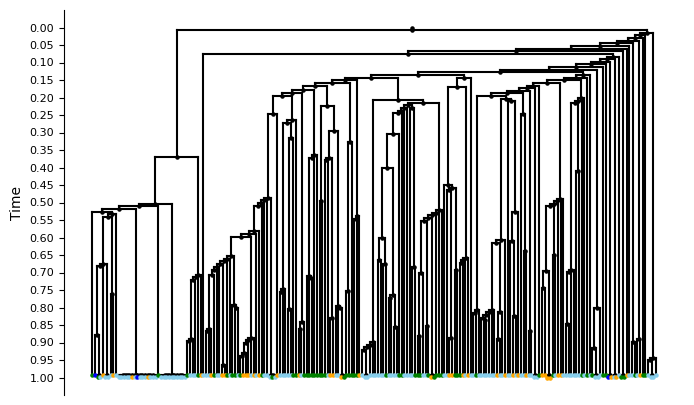

In [18]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [19]:
leaves = [n for n, d in T.out_degree() if d == 0]

In [20]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [21]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9924674051362167 1.0


In [22]:
EPS = 1e-4
scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

In [23]:
for u, v, d in T.edges(data=True):
    d['weight'] *= scale

In [24]:
for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    
    if dist > 1.0:
        parent = list(T.predecessors(leaf))[0]
        
        edge_length = T[parent][leaf]['weight']
        
        excess = dist - 1.0
        T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths

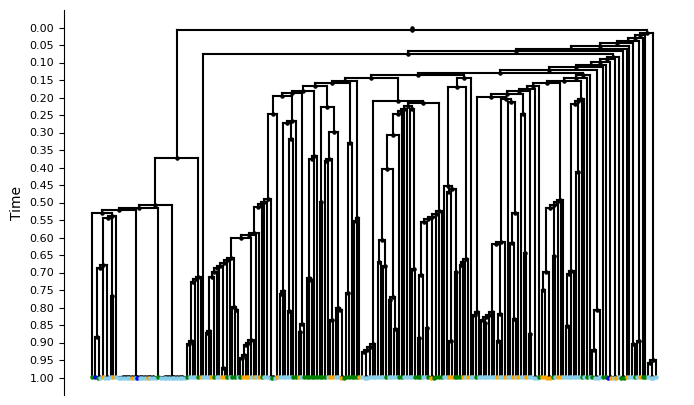

In [25]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [26]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [27]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9999 1.0


In [28]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int,
            {'Somite': 56, 'Endothelial': 3, 'NeuralTube': 116, 'NMPs': 39})

## Differentiation Map from CARTA

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:242: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


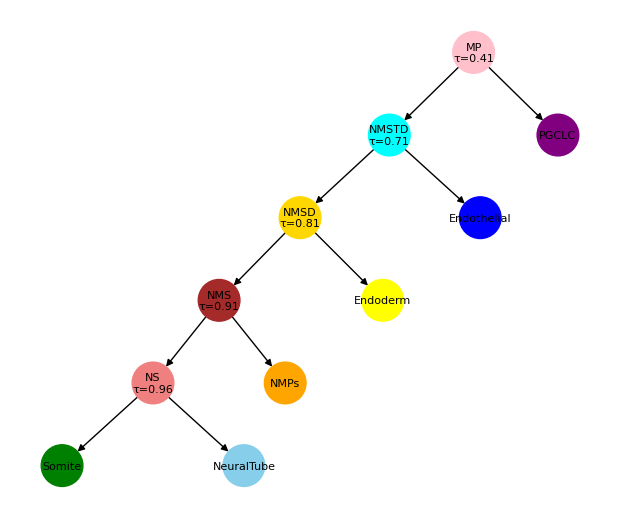

In [29]:
import string
from plotters import plot_differentiation_tree

diff_map_edges = [
    ("MP", "PGCLC"),
    ("MP", "NMSTD"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
]

a = 0.96
b = 0.05
c = 0.1
d = 0.1
e = 0.3

diff_times = {
    "MP":  a- b - c - d - e,
    "NMSTD": a - b - c - d,
    "NMSD": a - b - c,
    "NMS": a - b,
    "NS": a,
    "PGCLC": None,
    "Endothelial": None,
    "Endoderm": None,
    "NMPs": None,
    "Somite": None,
    "NeuralTube": None
}

diff_T = nx.DiGraph()


for k, v in diff_times.items():
    diff_T.add_node(k, diff_time=v)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

In [30]:
from likelihood import add_node_times
T = add_node_times(T, root=T.graph['root'])

In [31]:
rev_diff_T = diff_T.copy()
for n in diff_T.nodes():
    if diff_T.nodes[n]['diff_time'] is None: rev_diff_T.nodes[n]['diff_time'] = 0
    else: rev_diff_T.nodes[n]['diff_time'] = 1 - diff_T.nodes[n]['diff_time']

In [32]:
from likelihood import assign_states_to_internal_nodes

T = assign_states_to_internal_nodes(T, rev_diff_T, correct=True)

Children have > 1 types ['NMPs', 'Somite'] at 9.999860293596896e-05
Setting state for descendant 277 at 0.0 to ?
Setting state for descendant 278 at 0.0 to ?
Children have > 1 types ['NMPs', 'Somite'] at 9.99987001575331e-05
Setting state for descendant 209 at 0.0 to ?
Setting state for descendant 210 at 0.0 to ?
Children have > 1 types ['NeuralTube', 'Somite'] at 9.999903491764162e-05
Setting state for descendant 162 at 0.0 to ?
Setting state for descendant 163 at 0.0 to ?
Children have > 1 types ['NMPs', 'Endothelial'] at 9.999912332281369e-05
Setting state for descendant 402 at 0.0 to ?
Setting state for descendant 403 at 0.0 to ?
Children have > 1 types ['NeuralTube', 'Somite'] at 9.999982578401401e-05
Setting state for descendant 16 at 0.0 to ?
Setting state for descendant 15 at 0.0 to ?
Children have > 1 types ['NMPs', 'NeuralTube'] at 9.999983868236306e-05
Setting state for descendant 405 at 0.0 to ?
Setting state for descendant 406 at 0.0 to ?
Children have > 1 types ['NMPs', '

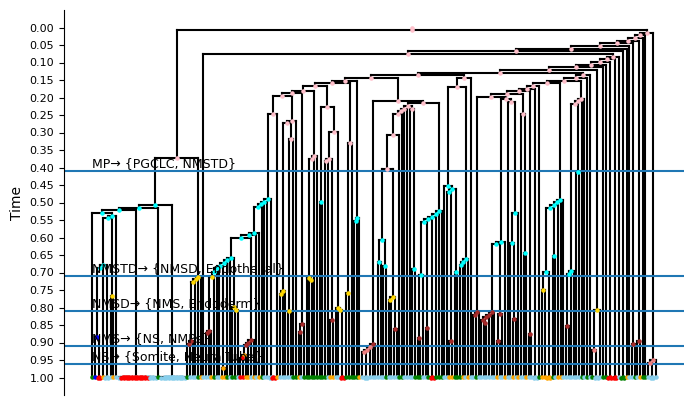

In [33]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T)

In [34]:
types = list(diff_T.nodes())

transition_maps = [
    (i, succ)
    for i in diff_T.nodes()
    if (succ := list(diff_T.successors(i)))
]

print(types)
print(transition_maps)

['MP', 'NMSTD', 'NMSD', 'NMS', 'NS', 'PGCLC', 'Endothelial', 'Endoderm', 'NMPs', 'Somite', 'NeuralTube']
[('MP', ['PGCLC', 'NMSTD']), ('NMSTD', ['NMSD', 'Endothelial']), ('NMSD', ['NMS', 'Endoderm']), ('NMS', ['NS', 'NMPs']), ('NS', ['Somite', 'NeuralTube'])]


In [35]:
T.nodes(data=True)

NodeDataView({0: {'name': 'root', 'dist': 0.0, 'is_leaf': False, 'T': 1, 'state': 'MP'}, 1: {'name': '', 'dist': 0.007532591442360219, 'is_leaf': False, 'T': 0.9924109969312471, 'state': 'MP'}, 2: {'name': 'node_322', 'dist': 0.3623537967532978, 'is_leaf': False, 'T': 0.6273435302330392, 'state': 'MP'}, 3: {'name': 'node_334', 'dist': 0.13324683365271192, 'is_leaf': False, 'T': 0.49309881017489254, 'state': 'NMSTD'}, 4: {'name': 'node_336', 'dist': 0.007532591725965801, 'is_leaf': False, 'T': 0.4855098068204101, 'state': 'NMSTD'}, 5: {'name': 'node_338', 'dist': 0.007532591643725337, 'is_leaf': False, 'T': 0.4779208035487841, 'state': 'NMSTD'}, 6: {'name': 'node_339', 'dist': 0.007532591598189932, 'is_leaf': False, 'T': 0.47033180032303445, 'state': 'NMSTD'}, 7: {'name': 'GAATCACGTTAGCTAC-1', 'dist': 0.466736408457954, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteSclero', 'T': 9.999986097819491e-05}, 8: {'name': 'node_340', 'dist': 0.00753259166403

In [36]:
T.edges(data=True)

OutEdgeDataView([(0, 1, {'weight': 0.0075890030687529066}), (1, 2, {'weight': 0.36506746669820783}), (1, 85, {'weight': 0.007589003020219818}), (2, 3, {'weight': 0.13424472005814667}), (2, 74, {'weight': 0.3392308988226696}), (3, 4, {'weight': 0.0075890033544824135}), (3, 55, {'weight': 0.49299881031391435}), (4, 5, {'weight': 0.007589003271626049}), (4, 54, {'weight': 0.485409806959432}), (5, 6, {'weight': 0.00758900322574963}), (5, 25, {'weight': 0.4778208036878059}), (6, 7, {'weight': 0.47023180046205626}), (6, 8, {'weight': 0.007589003292084071}), (8, 9, {'weight': 0.00758900340433337}), (8, 24, {'weight': 0.4626427972258149}), (9, 10, {'weight': 0.13492753202198404}), (9, 21, {'weight': 0.22257158633474725}), (10, 11, {'weight': 0.0075890039943117184}), (10, 18, {'weight': 0.3201262617788489}), (11, 12, {'weight': 0.19736138062036282}), (11, 17, {'weight': 0.3125372577845373}), (12, 13, {'weight': 0.11517587716417445}), (12, 14, {'weight': 0.11517587716417445}), (14, 15, {'weight'

### Considering all trees together

In [37]:
len(data)

12

In [38]:
Ts = []

for t in data[2:3]:
    T = ete_to_nx(t)
    Ts.append(T)

In [39]:
## scale edges
EPS = 1e-4

for T in Ts:
    leaves = [n for n, d in T.out_degree() if d == 0]
    # If edges have weight attribute 'length' or similar
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1
    for u, v, d in T.edges(data=True):
        d['weight'] *= scale
    
    for leaf in leaves:
        dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
        
        if dist > 1.0:
            parent = list(T.predecessors(leaf))[0]
            
            edge_length = T[parent][leaf]['weight']
            
            excess = dist - 1.0
            T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths

    for n in T.nodes():
        if T.nodes[n].get('state') == "PCGLC":
            T.nodes[n]['state'] = "PGCLC"

In [40]:
## add node times and assign internal states
for i, T in enumerate(Ts):
    print('='*50)
    print('Processing tree', i)
    print('='*50)
    T = add_node_times(T, root=T.graph['root'])
    T = assign_states_to_internal_nodes(T, rev_diff_T, correct=True)

Processing tree 0
Children have > 1 types ['NeuralTube', 'Endothelial'] at 0.006480521179465182
Setting state for descendant 249 at 0.0 to ?
Setting state for descendant 250 at 0.0 to ?
Children have > 1 types ['NS', 'Endothelial'] at 0.07652004638506071
Setting state for descendant 106 at 0.006480522412593115 to ?
Setting state for descendant 107 at 0.006480522412593115 to ?


Drawing tree 0


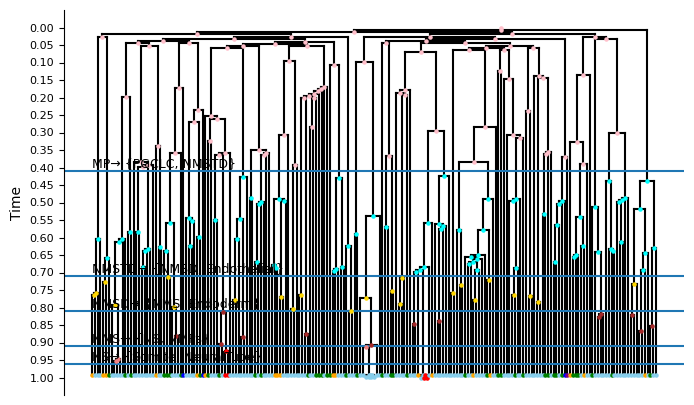

In [41]:
## draw trees
for i, T in enumerate(Ts):
    print('='*50)
    print('Drawing tree', i)
    print('='*50)
    draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T)

In [32]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

from likelihood import calculate_log_likelihood_graph_diff_opt


MAX_DEATH = 1.0
MAX_BIRTH = 10.0


def unpack_params(theta):

    k = 0

    # -------------------------
    # Death rates: (0, 1)
    # -------------------------
    death = {}
    for t in types:
        death[t] = MAX_DEATH * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Birth rates: (death, 10)
    # -------------------------
    birth = {}
    for t in types:
        birth[t] = death[t] + (MAX_BIRTH - death[t]) * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Transition matrix
    # -------------------------
    Q = pd.DataFrame(0.0, index=types, columns=types)

    for i, transition_to in transition_maps:

        logits = []
        js = []

        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)
        logits -= np.max(logits)

        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]

    return birth, death, Q


def neg_log_likelihood(theta, trees, diff_T, sampling_rate=1.0):

    birth, death, Q = unpack_params(theta)

    total_nll = 0.0

    for cell_lineage_T in trees:

        # try:
        l = calculate_log_likelihood_graph_diff_opt(
            T=cell_lineage_T,
            birth_rates=birth,
            death_rates=death,
            sampling_rate=sampling_rate,
            transition_probabilities=Q,
            diff_T=diff_T
        )
        
        total_nll += -l

    return total_nll


def pack_initial():

    params = []

    # death parameters
    for t in types:
        params.append(0.0)

    # birth parameters
    for t in types:
        params.append(0.0)

    # transition logits
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(0.0)

    return np.array(params)


def find_params(trees, diff_T):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, diff_T, 0.5),
        method="L-BFGS-B"
    )

    print(result)

    birth, death, Q = unpack_params(result.x)

    return birth, death, Q

In [324]:
birth_rates, death_rates, Q = find_params(Ts, rev_diff_T)
birth_rates, death_rates, Q

TypeError: bad operand type for unary -: 'tuple'

In [33]:
plot_differentiation_tree(diff_T, birth_rates, death_rates, transition_probabilities=Q)

NameError: name 'birth_rates' is not defined

## Multiple diff times

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:242: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


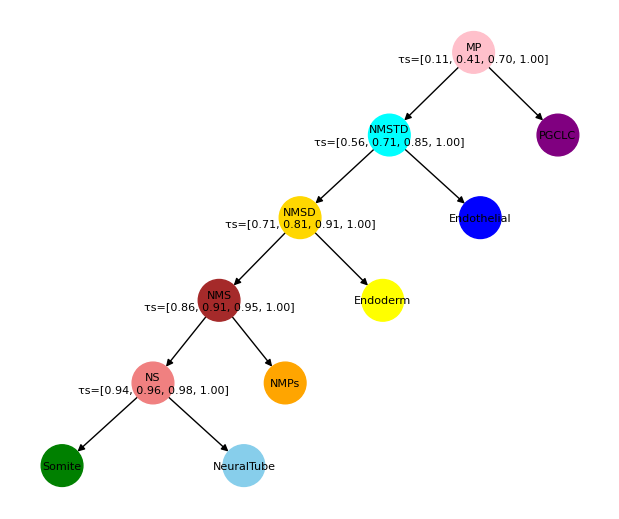

In [34]:
import string
from plotters import plot_differentiation_tree

diff_map_edges = [
    ("MP", "PGCLC"),
    ("MP", "NMSTD"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
]

a = 0.96
b = 0.05
c = 0.1
d = 0.1
e = 0.3

mp = a - b - c - d - e
nmstd = a - b - c - d
nmsd = a - b - c
nms = a - b
ns = a

EPS = 1e-10

# diff_ts = {
#     "MP":  [mp, 1 - 5*EPS],
#     "NMSTD": [nmstd, 1 - 4*EPS],
#     "NMSD": [nmsd, 1 - 3*EPS],
#     "NMS": [nms, 1 - 2*EPS],
#     "NS": [ns, 1 - 1*EPS],
#     "PGCLC": [],
#     "Endothelial": [],
#     "Endoderm": [],
#     "NMPs": [],
#     "Somite": [],
#     "NeuralTube": []
# }

diff_ts = {
    "MP":  [1 - 1.5 * (1 - mp), mp, 1 - 0.5 * (1 - mp), 1 - 5*EPS],
    "NMSTD": [1 - 1.5 * (1 - nmstd), nmstd, 1 - 0.5 * (1 - nmstd), 1 - 4*EPS],
    "NMSD": [1 - 1.5 * (1 - nmsd), nmsd, 1 - 0.5 * (1 - nmsd), 1 - 3*EPS],
    "NMS": [1 - 1.5 * (1 - nms), nms, 1 - 0.5 * (1 - nms), 1 - 2*EPS],
    "NS": [1 - 1.5 * (1 - ns), ns, 1 - 0.5 * (1 - ns), 1 - 1*EPS],
    "PGCLC": [],
    "Endothelial": [],
    "Endoderm": [],
    "NMPs": [],
    "Somite": [],
    "NeuralTube": []
}

diff_T = nx.DiGraph()


for k, v in diff_ts.items():
    diff_T.add_node(k, diff_times=v)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

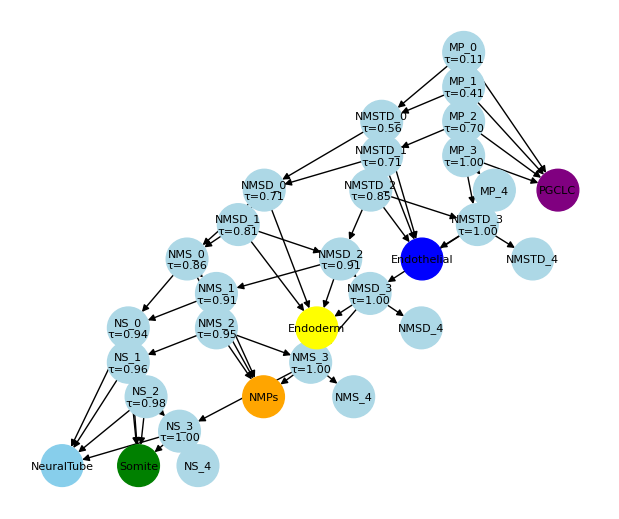

In [35]:
inflated_diff_T = nx.DiGraph()

for n in diff_T.nodes():
    diff_times = diff_T.nodes[n]['diff_times']
    if not diff_times:
        inflated_diff_T.add_node(n, diff_time=None)
    else:
        for i, t in enumerate(diff_times + [None]):
            inflated_diff_T.add_node(f"{n}_{i}", diff_time=t)


for u, v in diff_T.edges():
    for i, t in enumerate(diff_T.nodes[u]['diff_times']):
        nearest_v = None
        nearest_v_time = float('inf')
        v_diff_times = diff_T.nodes[v]['diff_times']

        if not v_diff_times:

            inflated_diff_T.add_edge(f"{u}_{i}", v)
            
        else:

            for j, t2 in enumerate(v_diff_times):
                if t2 > t and t2 < nearest_v_time:
                    nearest_v = j
                    nearest_v_time = t2
            
            if nearest_v is not None:
                inflated_diff_T.add_edge(f"{u}_{i}", f"{v}_{nearest_v}")

for n in diff_T.nodes():
    diff_times = diff_T.nodes[n]['diff_times']
    if diff_times and len(diff_times) > 1:
        for i in range(len(diff_times)):
            inflated_diff_T.add_edge(f"{n}_{i}", f"{n}_{i+1}")


plot_differentiation_tree(inflated_diff_T)

In [36]:
inflated_diff_T.nodes(data=True)

NodeDataView({'MP_0': {'diff_time': 0.11499999999999988}, 'MP_1': {'diff_time': 0.41}, 'MP_2': {'diff_time': 0.705}, 'MP_3': {'diff_time': 0.9999999995}, 'MP_4': {'diff_time': None}, 'NMSTD_0': {'diff_time': 0.565}, 'NMSTD_1': {'diff_time': 0.71}, 'NMSTD_2': {'diff_time': 0.855}, 'NMSTD_3': {'diff_time': 0.9999999996}, 'NMSTD_4': {'diff_time': None}, 'NMSD_0': {'diff_time': 0.7149999999999999}, 'NMSD_1': {'diff_time': 0.8099999999999999}, 'NMSD_2': {'diff_time': 0.905}, 'NMSD_3': {'diff_time': 0.9999999997}, 'NMSD_4': {'diff_time': None}, 'NMS_0': {'diff_time': 0.8649999999999999}, 'NMS_1': {'diff_time': 0.9099999999999999}, 'NMS_2': {'diff_time': 0.955}, 'NMS_3': {'diff_time': 0.9999999998}, 'NMS_4': {'diff_time': None}, 'NS_0': {'diff_time': 0.94}, 'NS_1': {'diff_time': 0.96}, 'NS_2': {'diff_time': 0.98}, 'NS_3': {'diff_time': 0.9999999999}, 'NS_4': {'diff_time': None}, 'PGCLC': {'diff_time': None}, 'Endothelial': {'diff_time': None}, 'Endoderm': {'diff_time': None}, 'NMPs': {'diff_t

In [37]:
inflated_diff_T.edges(data=True)

OutEdgeDataView([('MP_0', 'PGCLC', {}), ('MP_0', 'NMSTD_0', {}), ('MP_0', 'MP_1', {}), ('MP_1', 'PGCLC', {}), ('MP_1', 'NMSTD_0', {}), ('MP_1', 'MP_2', {}), ('MP_2', 'PGCLC', {}), ('MP_2', 'NMSTD_1', {}), ('MP_2', 'MP_3', {}), ('MP_3', 'PGCLC', {}), ('MP_3', 'NMSTD_3', {}), ('MP_3', 'MP_4', {}), ('NMSTD_0', 'NMSD_0', {}), ('NMSTD_0', 'Endothelial', {}), ('NMSTD_0', 'NMSTD_1', {}), ('NMSTD_1', 'NMSD_0', {}), ('NMSTD_1', 'Endothelial', {}), ('NMSTD_1', 'NMSTD_2', {}), ('NMSTD_2', 'NMSD_2', {}), ('NMSTD_2', 'Endothelial', {}), ('NMSTD_2', 'NMSTD_3', {}), ('NMSTD_3', 'NMSD_3', {}), ('NMSTD_3', 'Endothelial', {}), ('NMSTD_3', 'NMSTD_4', {}), ('NMSD_0', 'NMS_0', {}), ('NMSD_0', 'Endoderm', {}), ('NMSD_0', 'NMSD_1', {}), ('NMSD_1', 'NMS_0', {}), ('NMSD_1', 'Endoderm', {}), ('NMSD_1', 'NMSD_2', {}), ('NMSD_2', 'NMS_1', {}), ('NMSD_2', 'Endoderm', {}), ('NMSD_2', 'NMSD_3', {}), ('NMSD_3', 'NMS_3', {}), ('NMSD_3', 'Endoderm', {}), ('NMSD_3', 'NMSD_4', {}), ('NMS_0', 'NS_0', {}), ('NMS_0', 'NMPs'

In [42]:
Ts = []

for t in data:
    T = ete_to_nx(t)
    Ts.append(T)

In [43]:
## scale edges
EPS = 1e-4

for T in Ts:
    leaves = [n for n, d in T.out_degree() if d == 0]
    # If edges have weight attribute 'length' or similar
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1
    for u, v, d in T.edges(data=True):
        d['weight'] *= scale
    
    for leaf in leaves:
        dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
        
        if dist > 1.0:
            parent = list(T.predecessors(leaf))[0]
            
            edge_length = T[parent][leaf]['weight']
            
            excess = dist - 1.0
            T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths
    
    for n in T.nodes():
        if T.nodes[n].get('state') == "PCGLC":
            T.nodes[n]['state'] = "PGCLC"

In [44]:
from dataprocessor import export_tree

## add node times and assign internal states
for i, T in enumerate(Ts):
    print('='*50)
    print('Processing tree', i)
    print('='*50)
    T = add_node_times(T, root=T.graph['root'])

    leaves = [n for n, d in T.out_degree() if d == 0]
    for leaf in leaves:
        T.nodes[leaf]['T'] = 0.0

    # T = assign_states_to_internal_nodes(T, rev_diff_T, correct=True)

    export_tree(T, f"../data/troupe/TLS_processed/nodes_{i}.csv", f"../data/troupe/TLS_processed/edges_{i}.csv")

Processing tree 0
Processing tree 1
Processing tree 2
Processing tree 3
Processing tree 4
Processing tree 5
Processing tree 6
Processing tree 7
Processing tree 8
Processing tree 9
Processing tree 10
Processing tree 11


In [45]:
## draw trees
for i, T in enumerate(Ts):
    print('='*50)
    print('Drawing tree', i)
    print('='*50)
    draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=inflated_diff_T)

Drawing tree 0


NameError: name 'inflated_diff_T' is not defined

In [42]:
types = sorted(list(inflated_diff_T.nodes()))

transition_maps = [
    (i, list(inflated_diff_T.successors(i)))
    for i in inflated_diff_T.nodes()
]

types_unq = sorted(list(set([t.split('_')[0] for t in types])))

transition_maps_unq = [
    (i, succ)
    for i in types_unq
    if (succ := list(diff_T.successors(i)))
]



print(types)
print(transition_maps)
print(transition_maps_unq)

['Endoderm', 'Endothelial', 'MP_0', 'MP_1', 'MP_2', 'MP_3', 'MP_4', 'NMPs', 'NMSD_0', 'NMSD_1', 'NMSD_2', 'NMSD_3', 'NMSD_4', 'NMSTD_0', 'NMSTD_1', 'NMSTD_2', 'NMSTD_3', 'NMSTD_4', 'NMS_0', 'NMS_1', 'NMS_2', 'NMS_3', 'NMS_4', 'NS_0', 'NS_1', 'NS_2', 'NS_3', 'NS_4', 'NeuralTube', 'PGCLC', 'Somite']
[('MP_0', ['PGCLC', 'NMSTD_0', 'MP_1']), ('MP_1', ['PGCLC', 'NMSTD_0', 'MP_2']), ('MP_2', ['PGCLC', 'NMSTD_1', 'MP_3']), ('MP_3', ['PGCLC', 'NMSTD_3', 'MP_4']), ('MP_4', []), ('NMSTD_0', ['NMSD_0', 'Endothelial', 'NMSTD_1']), ('NMSTD_1', ['NMSD_0', 'Endothelial', 'NMSTD_2']), ('NMSTD_2', ['NMSD_2', 'Endothelial', 'NMSTD_3']), ('NMSTD_3', ['NMSD_3', 'Endothelial', 'NMSTD_4']), ('NMSTD_4', []), ('NMSD_0', ['NMS_0', 'Endoderm', 'NMSD_1']), ('NMSD_1', ['NMS_0', 'Endoderm', 'NMSD_2']), ('NMSD_2', ['NMS_1', 'Endoderm', 'NMSD_3']), ('NMSD_3', ['NMS_3', 'Endoderm', 'NMSD_4']), ('NMSD_4', []), ('NMS_0', ['NS_0', 'NMPs', 'NMS_1']), ('NMS_1', ['NS_0', 'NMPs', 'NMS_2']), ('NMS_2', ['NS_1', 'NMPs', 'NMS_3

In [50]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

from likelihood import calculate_log_likelihood_graph_diff_opt2, calculate_log_likelihood_graph_diff


MAX_DEATH = 1.0
MAX_BIRTH = 10.0


def unpack_params(theta):

    k = 0

    # -------------------------
    # Death rates: (0, 1)
    # -------------------------
    death = {}
    for tu in types_unq:
        for t in types:
            if t.split('_')[0] == tu:
                death[t] = MAX_DEATH * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Birth rates: (death, 10)
    # -------------------------
    birth = {}
    for tu in types_unq:
        for t in types:
            if t.split('_')[0] == tu:
                birth[t] = death[t] + (MAX_BIRTH - death[t]) * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Transition matrix
    # -------------------------
    Qs = pd.DataFrame(0.0, index=types_unq, columns=types_unq)

    for i, transition_to in transition_maps_unq:

        if len(transition_to) == 0:
            # absorbing state
            Q.loc[i, i] = 1.0
            continue

        logits = []
        js = []

        for j in [i] + transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)
        logits -= np.max(logits)

        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Qs.loc[i, j] = probs[idx]
    
    Q = pd.DataFrame(0.0, index=types, columns=types)
    for i, transition_to in transition_maps:
        for j in transition_to:
            Q.loc[i, j] = Qs.loc[i.split('_')[0], j.split('_')[0]]

    return birth, death, Q


def neg_log_likelihood(theta, trees, diff_T, sampling_rate=1.0):

    print("." , end="")

    birth, death, Q = unpack_params(theta)

    total_nll = 0.0

    for cell_lineage_T in trees:

        # try:
        l, _, _ = calculate_log_likelihood_graph_diff_opt2(
            T=cell_lineage_T,
            birth_rates=birth,
            death_rates=death,
            sampling_rate=sampling_rate,
            transition_probabilities=Q,
            diff_T=diff_T
        )
        
        total_nll += -l

    return total_nll


def pack_initial():

    params = []

    # death parameters
    for t in types_unq:
        params.append(0.0)

    # birth parameters
    for t in types_unq:
        params.append(0.0)

    # transition logits
    for i, transition_to in transition_maps_unq:
        for j in [i] + transition_to:
            params.append(0.0)

    return np.array(params)
    

def find_params(trees, diff_T):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, diff_T, 0.5),
        method="L-BFGS-B"
    )

    print(result)

    birth, death, Q = unpack_params(result.x)

    return birth, death, Q

In [51]:
rev_diff_T = inflated_diff_T.copy()
for n in inflated_diff_T.nodes():
    if inflated_diff_T.nodes[n]['diff_time'] is None: rev_diff_T.nodes[n]['diff_time'] = 0
    else: rev_diff_T.nodes[n]['diff_time'] = 1 - inflated_diff_T.nodes[n]['diff_time']

In [52]:
rev_diff_T.nodes(data=True)

NodeDataView({'MP_0': {'diff_time': 0.8850000000000001}, 'MP_1': {'diff_time': 0.5900000000000001}, 'MP_2': {'diff_time': 0.29500000000000004}, 'MP_3': {'diff_time': 5.000000413701855e-10}, 'MP_4': {'diff_time': 0}, 'NMSTD_0': {'diff_time': 0.43500000000000005}, 'NMSTD_1': {'diff_time': 0.29000000000000004}, 'NMSTD_2': {'diff_time': 0.14500000000000002}, 'NMSTD_3': {'diff_time': 4.000000330961484e-10}, 'NMSTD_4': {'diff_time': 0}, 'NMSD_0': {'diff_time': 0.28500000000000014}, 'NMSD_1': {'diff_time': 0.19000000000000006}, 'NMSD_2': {'diff_time': 0.09499999999999997}, 'NMSD_3': {'diff_time': 3.000000248221113e-10}, 'NMSD_4': {'diff_time': 0}, 'NMS_0': {'diff_time': 0.13500000000000012}, 'NMS_1': {'diff_time': 0.09000000000000008}, 'NMS_2': {'diff_time': 0.04500000000000004}, 'NMS_3': {'diff_time': 2.000000165480742e-10}, 'NMS_4': {'diff_time': 0}, 'NS_0': {'diff_time': 0.06000000000000005}, 'NS_1': {'diff_time': 0.040000000000000036}, 'NS_2': {'diff_time': 0.020000000000000018}, 'NS_3': 

In [53]:
rev_diff_T.edges(data=True)

OutEdgeDataView([('MP_0', 'PGCLC', {}), ('MP_0', 'NMSTD_0', {}), ('MP_0', 'MP_1', {}), ('MP_1', 'PGCLC', {}), ('MP_1', 'NMSTD_0', {}), ('MP_1', 'MP_2', {}), ('MP_2', 'PGCLC', {}), ('MP_2', 'NMSTD_1', {}), ('MP_2', 'MP_3', {}), ('MP_3', 'PGCLC', {}), ('MP_3', 'NMSTD_3', {}), ('MP_3', 'MP_4', {}), ('NMSTD_0', 'NMSD_0', {}), ('NMSTD_0', 'Endothelial', {}), ('NMSTD_0', 'NMSTD_1', {}), ('NMSTD_1', 'NMSD_0', {}), ('NMSTD_1', 'Endothelial', {}), ('NMSTD_1', 'NMSTD_2', {}), ('NMSTD_2', 'NMSD_2', {}), ('NMSTD_2', 'Endothelial', {}), ('NMSTD_2', 'NMSTD_3', {}), ('NMSTD_3', 'NMSD_3', {}), ('NMSTD_3', 'Endothelial', {}), ('NMSTD_3', 'NMSTD_4', {}), ('NMSD_0', 'NMS_0', {}), ('NMSD_0', 'Endoderm', {}), ('NMSD_0', 'NMSD_1', {}), ('NMSD_1', 'NMS_0', {}), ('NMSD_1', 'Endoderm', {}), ('NMSD_1', 'NMSD_2', {}), ('NMSD_2', 'NMS_1', {}), ('NMSD_2', 'Endoderm', {}), ('NMSD_2', 'NMSD_3', {}), ('NMSD_3', 'NMS_3', {}), ('NMSD_3', 'Endoderm', {}), ('NMSD_3', 'NMSD_4', {}), ('NMS_0', 'NS_0', {}), ('NMS_0', 'NMPs'

In [54]:
from dataprocessor import export_diff_T, STATE_TO_ID

export_diff_T(rev_diff_T, STATE_TO_ID, "../data/troupe/TLS_processed/diff_nodes.csv", "../data/troupe/TLS_processed/diff_edges.csv")

{'PGCLC': 0,
 'PCGLC': 0,
 'Endothelial': 1,
 'Endoderm': 2,
 'NMPs': 3,
 'Somite': 4,
 'NeuralTube': 5,
 'MP': 6,
 'NMSTD': 7,
 'NMSD': 8,
 'NMS': 9,
 'NS': 10,
 'MP_0': 11,
 'MP_1': 12,
 'MP_2': 13,
 'MP_3': 14,
 'MP_4': 15,
 'NMSTD_0': 16,
 'NMSTD_1': 17,
 'NMSTD_2': 18,
 'NMSTD_3': 19,
 'NMSTD_4': 20,
 'NMSD_0': 21,
 'NMSD_1': 22,
 'NMSD_2': 23,
 'NMSD_3': 24,
 'NMSD_4': 25,
 'NMS_0': 26,
 'NMS_1': 27,
 'NMS_2': 28,
 'NMS_3': 29,
 'NMS_4': 30,
 'NS_0': 31,
 'NS_1': 32,
 'NS_2': 33,
 'NS_3': 34,
 'NS_4': 35}

In [56]:
birth_rates, death_rates, Q = find_params(Ts, rev_diff_T)
birth_rates, death_rates, Q

.{'Endoderm': np.float64(5.25), 'Endothelial': np.float64(5.25), 'MP_0': np.float64(5.25), 'MP_1': np.float64(5.25), 'MP_2': np.float64(5.25), 'MP_3': np.float64(5.25), 'MP_4': np.float64(5.25), 'NMPs': np.float64(5.25), 'NMS_0': np.float64(5.25), 'NMS_1': np.float64(5.25), 'NMS_2': np.float64(5.25), 'NMS_3': np.float64(5.25), 'NMS_4': np.float64(5.25), 'NMSD_0': np.float64(5.25), 'NMSD_1': np.float64(5.25), 'NMSD_2': np.float64(5.25), 'NMSD_3': np.float64(5.25), 'NMSD_4': np.float64(5.25), 'NMSTD_0': np.float64(5.25), 'NMSTD_1': np.float64(5.25), 'NMSTD_2': np.float64(5.25), 'NMSTD_3': np.float64(5.25), 'NMSTD_4': np.float64(5.25), 'NS_0': np.float64(5.25), 'NS_1': np.float64(5.25), 'NS_2': np.float64(5.25), 'NS_3': np.float64(5.25), 'NS_4': np.float64(5.25), 'NeuralTube': np.float64(5.25), 'PGCLC': np.float64(5.25), 'Somite': np.float64(5.25)}
{'Endoderm': np.float64(0.5), 'Endothelial': np.float64(0.5), 'MP_0': np.float64(0.5), 'MP_1': np.float64(0.5), 'MP_2': np.float64(0.5), 'MP_3

TypeError: cannot unpack non-iterable NoneType object

In [49]:
l, LL, U = calculate_log_likelihood_graph_diff(
    T=Ts[0],
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rate=0.5,
    transition_probabilities=Q,
    diff_T=rev_diff_T
)

print(l)

TypeError: list indices must be integers or slices, not str

In [358]:
# max_LL = defaultdict(lambda: float('-inf'))

# for (u, v, t, state), val in LL.items():
#     key = (u, v)
#     max_LL[key] = max(max_LL[key], val)

# max_LL = dict(max_LL)

# max_LL

In [359]:
# bad_keys = [k for k, v in max_LL.items() if v == float('-inf')]

# print(bad_keys)

In [360]:
# Q

In [361]:
# for k, v in LL.items():
#     # if k[0] == 336 and k[1] == 346:
#     # if k[0] == 336 and k[1] == 346 and k[3].startswith("MP"):
#     if k[0] == 336 and k[1] == 346 and k[3].startswith("PGCLC"):
#         print(k, v)

In [362]:
# T.nodes[bad_keys[0][0]]

In [363]:
# list(T.successors(result[0][1]))

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  


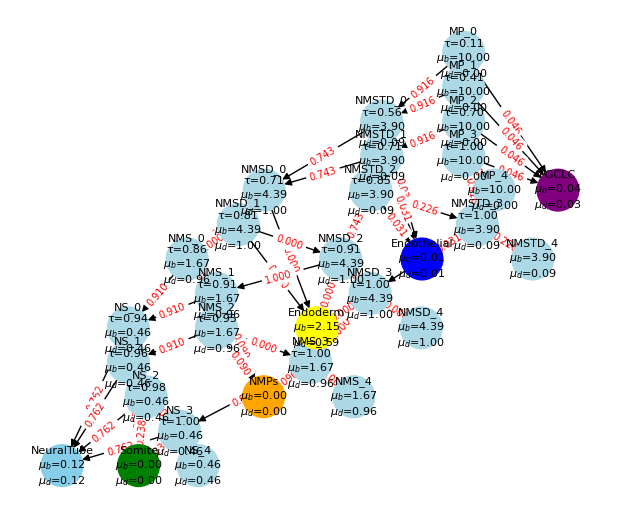

In [364]:
plot_differentiation_tree(inflated_diff_T, birth_rates, death_rates, transition_probabilities=Q)

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:62: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  # ---------


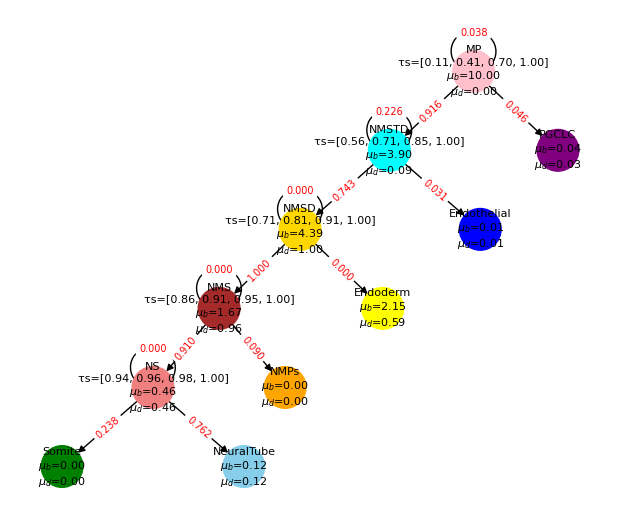

In [367]:
plot_differentiation_tree(diff_T, birth_rates, death_rates, transition_probabilities=Q, deflate_labels=True)